In [1]:
# carregar base

import pandas as pd
from pathlib import Path

df = pd.read_csv(Path.home() / "Downloads" / "genai_tools_platforms_2025.csv")
print(df.shape)

(113, 22)


## FASE 1: Business Understanding
### 1.1 Problema, público e decisão
Usuários frequentes de IA precisam escolher ferramentas para estudar, pesquisar, escrever, traduzir, analisar dados e criar apresentações. A hipótese de negócio é que a escolha sem apoio consome tempo, exige tentativas repetidas e pode produzir resultados inadequados. **Isso é uma hipótese a testar**, não um resultado já demonstrado.

**Público inicial:** estudantes, estagiários e profissionais. A persona do Canvas é Laura, 22 anos, universitária e estagiária. **Pergunta de negócio:** como reduzir o tempo de escolha de uma IA, considerando tarefa e restrições do usuário, sem prejudicar a qualidade?

**Produto proposto:** o usuário informa a tarefa e restrições (idioma, formato, orçamento, urgência e privacidade); o sistema sugere até três opções elegíveis, com justificativas e indicação de informações ainda não verificadas. A decisão final continua com o usuário.

---
## FASE 2: Data Understanding
### 2.1 Coleta e carregamento (equivalente ao TODO 1 do Titanic)
**Unidade observacional:** uma entrada de ferramenta/modelo/plataforma, e **não** uma tarefa avaliada. Usamos `df_bruto` e `df`, como no exercício da professora. O notebook procura automaticamente o CSV no diretório do notebook e na pasta Downloads do usuário, inclusive no Windows e no Mac. Se necessário, ajuste `CAMINHO_CSV`.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

NOME_ARQUIVO = 'genai_tools_platforms_2025.csv'
CAMINHO_CSV = None  # opcional: r'C:\Users\User\Downloads\genai_tools_platforms_2025.csv'
locais = ([Path(CAMINHO_CSV)] if CAMINHO_CSV else []) + [
    Path.cwd() / NOME_ARQUIVO,
    Path.home() / 'Downloads' / NOME_ARQUIVO,
    Path(r'C:\Users\User\Downloads\genai_tools_platforms_2025.csv')
]
arquivo = next((p for p in locais if p.is_file()), None)
if arquivo is None:
    raise FileNotFoundError('CSV não encontrado. Coloque genai_tools_platforms_2025.csv na pasta Downloads ou defina CAMINHO_CSV.')
df_bruto = pd.read_csv(arquivo)
df = df_bruto.copy()
print('Arquivo:', arquivo)
print('Dimensões:', df.shape)
display(df.head())

Arquivo: /Users/hyunahkim/Downloads/genai_tools_platforms_2025.csv
Dimensões: (113, 22)


,tool_name,company,category_canonical,modality_canonical,open_source,api_available,api_status,website,source_domain,release_year,...,mod_image,mod_video,mod_audio,mod_code,mod_design,mod_infra,mod_productivity,mod_safety,mod_multimodal,modality_count
0,ChatGPT,OpenAI,LLMs & Chat Assistants,multimodal,0,1,api,https://chatgpt.com,chatgpt.com,2022,...,0,0,0,0,0,0,0,0,1,0
1,Claude,Anthropic,LLMs & Chat Assistants,multimodal,0,1,api,https://claude.ai,claude.ai,2023,...,0,0,0,0,0,0,0,0,1,0
2,Gemini,Google,LLMs & Chat Assistants,multimodal,0,1,api,https://gemini.google.com,gemini.google.com,2023,...,0,0,0,0,0,0,0,0,1,0
3,Midjourney,Midjourney,Image Gen & Editing,image,0,0,unavailable,https://www.midjourney.com,midjourney.com,2022,...,1,0,0,0,0,0,0,0,0,1
4,Stable Diffusion,Stability AI,Image Gen & Editing,image,1,1,api,https://stability.ai/stable-image,stability.ai,2022,...,1,0,0,0,0,0,0,0,0,1


**Interpretação esperada:** 113 registros e 22 colunas na versão usada pelo grupo. `head()` mostra uma amostra, não permite concluir a representatividade do mercado.

### 2.2 Estrutura, tipos e valores ausentes

In [3]:
print('Dimensões:', df.shape)
print('Tipos de dados:')
print(df.dtypes)
print('\nValores ausentes por coluna:')
print(df.isna().sum().sort_values(ascending=False))
print('\nResumo numérico e categórico:')
display(df.describe(include='all').T)

Dimensões: (113, 22)
Tipos de dados:
tool_name                str
company                  str
category_canonical       str
modality_canonical       str
open_source            int64
api_available          int64
api_status               str
website                  str
source_domain            str
release_year           int64
years_since_release    int64
mod_text               int64
mod_image              int64
mod_video              int64
mod_audio              int64
mod_code               int64
mod_design             int64
mod_infra              int64
mod_productivity       int64
mod_safety             int64
mod_multimodal         int64
modality_count         int64
dtype: object

Valores ausentes por coluna:
tool_name              0
company                0
mod_multimodal         0
mod_safety             0
mod_productivity       0
mod_infra              0
mod_design             0
mod_code               0
mod_audio              0
mod_video              0
mod_image              0
mod_te

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tool_name,113,113,ChatGPT,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company,113,83,OpenAI,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_canonical,113,13,LLMs & Chat Assistants,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modality_canonical,113,10,multimodal,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open_source,113.0,NaN,NaN,NaN,0.371681,0.485406,0.0,0.0,0.0,1.0,1.0
api_available,113.0,NaN,NaN,NaN,0.946903,0.225226,0.0,1.0,1.0,1.0,1.0
api_status,113,2,api,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
website,113,105,https://platform.openai.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_domain,113,88,github.com,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,113.0,NaN,NaN,NaN,2022.20354,2.083778,2013.0,2022.0,2023.0,2023.0,2025.0


### 2.3 Duplicatas, domínios e valores inválidos
Verificamos duplicatas de linhas e nomes, indicadores fora de 0/1, anos fora de um intervalo plausível e coerência entre `api_available` e `api_status`. Não removemos dados automaticamente: primeiro diagnosticamos.

In [4]:
print('Linhas duplicadas:', int(df.duplicated().sum()))
print('Nomes duplicados:', int(df['tool_name'].duplicated().sum()))
print('Nomes distintos:', df['tool_name'].nunique())
flags = ['open_source','api_available'] + [c for c in df if c.startswith('mod_')]
for col in flags:
    invalidos = (~df[col].isin([0,1])) & df[col].notna()
    print(f'{col}: {int(invalidos.sum())} valores fora de 0/1')
print('Ano mínimo e máximo:', df['release_year'].min(), df['release_year'].max())
print('Anos fora de 1990–2025:', int((~df['release_year'].between(1990,2025)).sum()))
print('Status de API:', df['api_status'].value_counts(dropna=False).to_dict())
display(pd.crosstab(df['api_available'], df['api_status'], dropna=False))

Linhas duplicadas: 0
Nomes duplicados: 0
Nomes distintos: 113
open_source: 0 valores fora de 0/1
api_available: 0 valores fora de 0/1
mod_text: 0 valores fora de 0/1
mod_image: 0 valores fora de 0/1
mod_video: 0 valores fora de 0/1
mod_audio: 0 valores fora de 0/1
mod_code: 0 valores fora de 0/1
mod_design: 0 valores fora de 0/1
mod_infra: 0 valores fora de 0/1
mod_productivity: 0 valores fora de 0/1
mod_safety: 0 valores fora de 0/1
mod_multimodal: 0 valores fora de 0/1
Ano mínimo e máximo: 2013 2025
Anos fora de 1990–2025: 0
Status de API: {'api': 107, 'unavailable': 6}


api_status,api,unavailable
api_available,,
0,0,6
1,107,0


### 2.4 Consistência entre modalidades e contagem
No resumo inicial, `modality_count` variou de 0 a 1, embora o nome sugira uma contagem. Compararemos com a soma das flags para identificar divergências, **sem sobrescrever o dado original**.

In [5]:
colunas_mod = [c for c in df.columns if c.startswith('mod_')]
diagnostico_modalidades = df[['tool_name','modality_canonical','modality_count']].copy()
diagnostico_modalidades['soma_flags'] = df[colunas_mod].sum(axis=1)
diagnostico_modalidades['diverge'] = diagnostico_modalidades['modality_count'] != diagnostico_modalidades['soma_flags']
print('Divergências entre modality_count e soma das flags:', int(diagnostico_modalidades['diverge'].sum()))
display(diagnostico_modalidades.loc[diagnostico_modalidades['diverge']].head(15))
print('Distribuição da soma das flags:')
display(diagnostico_modalidades['soma_flags'].value_counts().sort_index())

Divergências entre modality_count e soma das flags: 55


,tool_name,modality_canonical,modality_count,soma_flags,diverge
0,ChatGPT,multimodal,0,1,True
1,Claude,multimodal,0,1,True
2,Gemini,multimodal,0,1,True
16,Perplexity,multimodal,0,1,True
17,Meta AI,multimodal,0,1,True
18,Mistral Le Chat,multimodal,0,1,True
19,Pinecone,infra,0,1,True
20,Weaviate,infra,0,1,True
21,Milvus,infra,0,1,True
22,Qdrant,infra,0,1,True


Distribuição da soma das flags:


soma_flags
1    113
Name: count, dtype: int64

### 2.5 Análise exploratória
Gráficos para observar **categorias, modalidades e restrições técnicas**, e não sobrevivência.

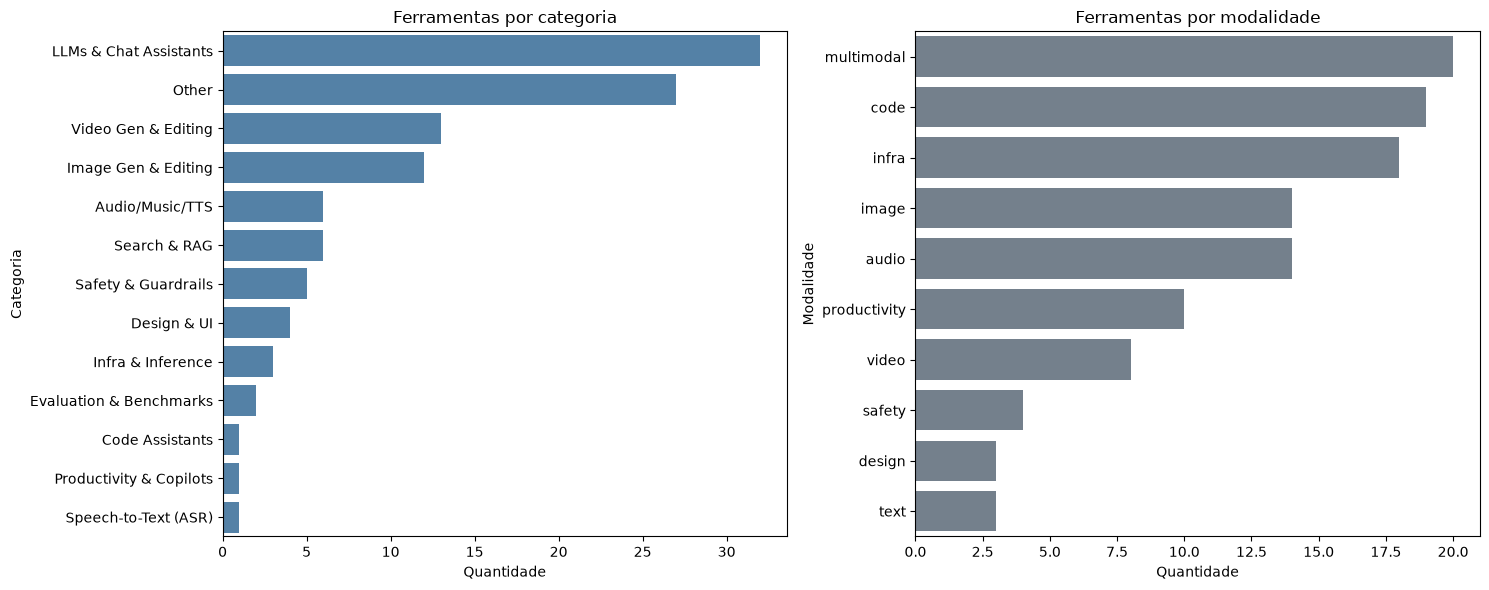

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ordem_cat = df['category_canonical'].value_counts().index
ordem_mod = df['modality_canonical'].value_counts().index
sns.countplot(data=df, y='category_canonical', order=ordem_cat, ax=axes[0], color='steelblue')
axes[0].set(title='Ferramentas por categoria', xlabel='Quantidade', ylabel='Categoria')
sns.countplot(data=df, y='modality_canonical', order=ordem_mod, ax=axes[1], color='slategray')
axes[1].set(title='Ferramentas por modalidade', xlabel='Quantidade', ylabel='Modalidade')
plt.tight_layout()
plt.show()

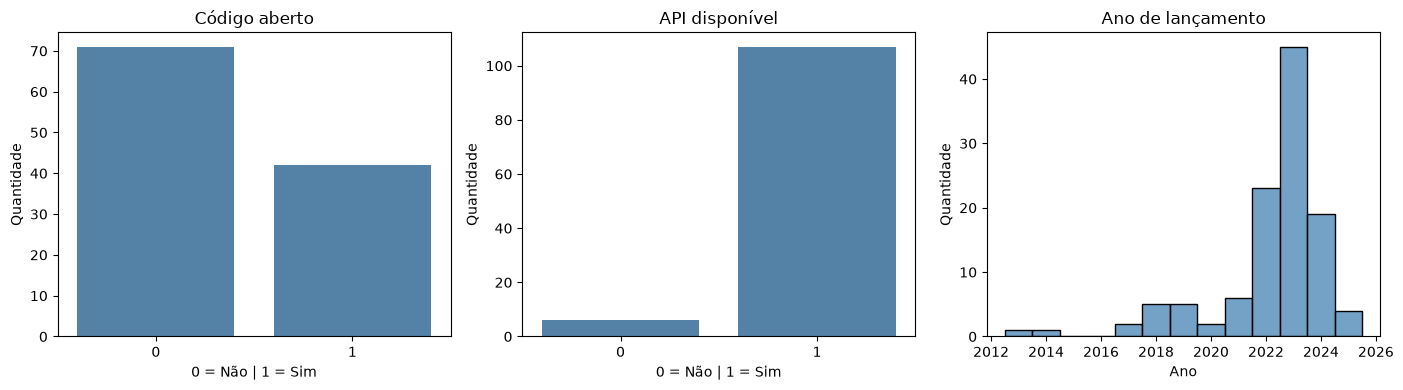

Open source: {0: 71, 1: 42}
API disponível: {1: 107, 0: 6}
Categorias: 13 | modalidades: 10


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=df, x='open_source', ax=axes[0], color='steelblue')
axes[0].set(title='Código aberto', xlabel='0 = Não | 1 = Sim', ylabel='Quantidade')
sns.countplot(data=df, x='api_available', ax=axes[1], color='steelblue')
axes[1].set(title='API disponível', xlabel='0 = Não | 1 = Sim', ylabel='Quantidade')
sns.histplot(data=df, x='release_year', discrete=True, ax=axes[2], color='steelblue')
axes[2].set(title='Ano de lançamento', xlabel='Ano', ylabel='Quantidade')
plt.tight_layout()
plt.show()
print('Open source:', df['open_source'].value_counts().to_dict())
print('API disponível:', df['api_available'].value_counts().to_dict())
print('Categorias:', df['category_canonical'].nunique(), '| modalidades:', df['modality_canonical'].nunique())

,open_source=0,open_source=1
category_canonical,,
Audio/Music/TTS,4,2
Code Assistants,1,0
Design & UI,4,0
Evaluation & Benchmarks,1,1
Image Gen & Editing,8,4
Infra & Inference,2,1
LLMs & Chat Assistants,18,14
Other,18,9
Productivity & Copilots,1,0


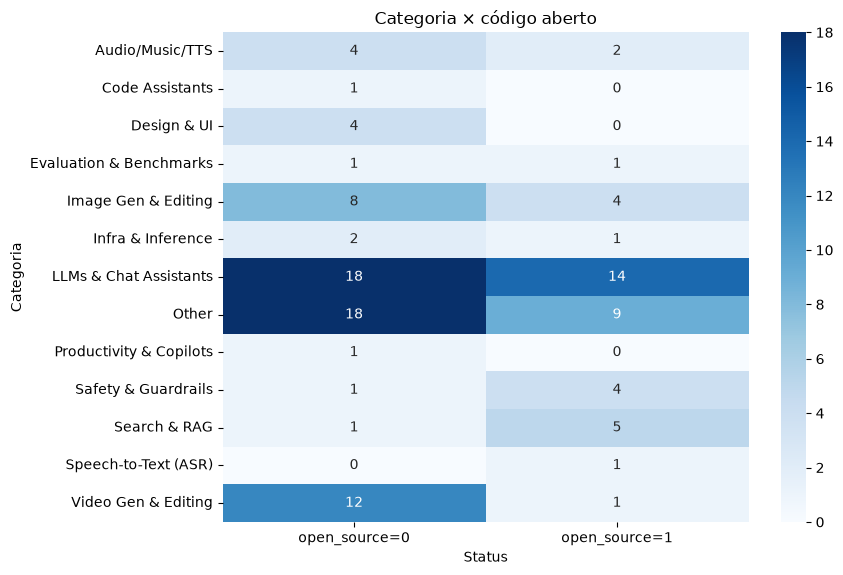

api_available,0,1
modality_canonical,,
audio,0,14
code,0,19
design,0,3
image,4,10
infra,1,17
multimodal,0,20
productivity,0,10
safety,0,4
text,0,3


In [8]:
tabela = pd.crosstab(df['category_canonical'], df['open_source'])
tabela.columns = [f'open_source={c}' for c in tabela.columns]
display(tabela)
fig, ax = plt.subplots(figsize=(9, max(5, len(tabela)*0.45)))
sns.heatmap(tabela, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title='Categoria × código aberto', xlabel='Status', ylabel='Categoria')
plt.tight_layout()
plt.show()
display(pd.crosstab(df['modality_canonical'], df['api_available']))

## 3. Características relevantes para uma recomendação empresarial - ampliação do Data Understanding

**Problema identificado:** as 22 colunas do catálogo descrevem ferramentas, mas não fornecem dados suficientes para determinar a melhor opção para uma tarefa concreta. A seleção deve combinar **necessidades do usuário**, **requisitos obrigatórios**, **características verificadas da ferramenta** e **resultados de testes**.

| Dimensão | Campos planejados | Uso na recomendação | Situação |
|---|---|---|---|
| Tarefa | `tarefas_suportadas`, `especialidade` | Compatibilidade com objetivo (analisar planilha, programar, pesquisar, resumir, criar slides) | Coletar e validar |
| Formatos | `formatos_entrada`, `formatos_saida` | Aceitar CSV/XLSX/PDF/imagem/áudio e entregar saída solicitada | Coletar e testar |
| Facilidade | `nivel_tecnico`, `sem_codigo`, `curva_aprendizado` | Adequação a iniciantes e usuários técnicos | Avaliação de usuários |
| Custo | `plano_gratuito`, `preco_mensal`, `limite_uso`, `moeda` | Compatibilidade com orçamento | Verificar por plano e data |
| Segurança | `politica_treinamento_dados`, `retencao`, `controles_empresariais` | Requisitos de confidencialidade | Documentação e contrato |
| Integrações | `integracoes`, `api_available` | Conexão com sistemas e fluxo de trabalho | API existe no catálogo; demais coletar |
| Idioma e acesso | `idiomas`, `regiao_disponivel`, `acessibilidade` | Uso na realidade do cliente | Coletar |
| Colaboração | `multiusuario`, `controle_acesso`, `suporte` | Operação em equipes | Coletar |
| Desempenho | `qualidade_teste`, `tempo_teste`, `taxa_sucesso`, `custo_por_tarefa` | Comparação empírica entre candidatos | Testes padronizados |

**Não confundir:** `release_year` é o lançamento, não a atualização da informação; `category_canonical` é uma categoria, não prova de competência; `api_available` não garante acesso à API em todos os planos.

**Unidade para o catálogo complementar:** ferramenta × versão/plano × data da verificação. **Unidade para o benchmark:** cenário × ferramenta × execução. A base original permanece intacta.

### Criar estrutura de coleta complementar 

O código abaixo cria um arquivo CSV com uma linha por ferramenta e colunas adicionais **vazias**, sinalizadas como `PENDENTE_VALIDACAO`. Assim, a equipe pode dividir a verificação por fontes oficiais e registrar evidências. **Células vazias significam desconhecido, não ausência de recurso.**

In [9]:
from pathlib import Path
campos_adicionais = [
    'versao_plano','data_verificacao','url_evidencia','tarefas_suportadas',
    'formatos_entrada','formatos_saida','nivel_tecnico','sem_codigo',
    'plano_gratuito','preco_mensal','moeda','limite_uso',
    'politica_treinamento_dados','retencao','controles_empresariais',
    'integracoes','idiomas','regiao_disponivel','acessibilidade',
    'multiusuario','controle_acesso','suporte','status_validacao'
]
coleta = df[['tool_name','company']].copy()
for campo in campos_adicionais:
    coleta[campo] = pd.NA
coleta['status_validacao'] = 'PENDENTE_VALIDACAO'
saida = Path.home() / 'Downloads' / 'coleta_complementar_ia.csv'
saida.parent.mkdir(parents=True, exist_ok=True)
coleta.to_csv(saida, index=False, encoding='utf-8-sig')
print('Planilha de coleta criada:', saida)
print('Ferramentas:', len(coleta), '| campos:', len(coleta.columns))
display(coleta.head(3))

Planilha de coleta criada: /Users/hyunahkim/Downloads/coleta_complementar_ia.csv
Ferramentas: 113 | campos: 25


,tool_name,company,versao_plano,data_verificacao,url_evidencia,tarefas_suportadas,formatos_entrada,formatos_saida,nivel_tecnico,sem_codigo,...,retencao,controles_empresariais,integracoes,idiomas,regiao_disponivel,acessibilidade,multiusuario,controle_acesso,suporte,status_validacao
0,ChatGPT,OpenAI,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,PENDENTE_VALIDACAO
1,Claude,Anthropic,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,PENDENTE_VALIDACAO
2,Gemini,Google,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,PENDENTE_VALIDACAO


### Formulário de necessidades do usuário (entrada do futuro recomendador)

A recomendação começa pela tarefa, não pela marca. Cada caso deve registrar: tarefa, formato de entrada, formato desejado, experiência técnica, orçamento, necessidade de API, exigência de open source, sensibilidade dos dados, idioma e integrações obrigatórias. Requisitos obrigatórios devem **excluir apenas incompatibilidades comprovadas**; valores desconhecidos precisam aparecer como **não verificados**, nunca como compatíveis.

In [10]:
necessidade_exemplo = {
    'tarefa': 'analise_dados',
    'formato_entrada': 'xlsx',
    'formato_saida': 'relatorio',
    'nivel_tecnico': 'iniciante',
    'orcamento_mensal': 0,
    'exige_api': False,
    'exige_open_source': False,
    'dados_confidenciais': True,
    'idioma': 'portugues',
    'integracao_obrigatoria': 'excel'
}
display(pd.DataFrame([necessidade_exemplo]).T.rename(columns={0:'Preferência / requisito'}))
print('A base atual NÃO permite verificar todos esses requisitos.')

,Preferência / requisito
tarefa,analise_dados
formato_entrada,xlsx
formato_saida,relatorio
nivel_tecnico,iniciante
orcamento_mensal,0
exige_api,False
exige_open_source,False
dados_confidenciais,True
idioma,portugues
integracao_obrigatoria,excel


A base atual NÃO permite verificar todos esses requisitos.


### Cobertura efetiva das características de decisão

A tabela diferencia variáveis presentes no CSV original de atributos que ainda faltam. **Presença da coluna não implica que seus valores sejam corretos ou atualizados.**

In [11]:
requisitos = {
    'Categoria geral': 'category_canonical',
    'Modalidade geral': 'modality_canonical',
    'Open source': 'open_source',
    'API': 'api_available',
    'Ano de lançamento': 'release_year',
    'Tarefa específica': 'tarefas_suportadas',
    'Formato de entrada': 'formatos_entrada',
    'Formato de saída': 'formatos_saida',
    'Nível técnico': 'nivel_tecnico',
    'Preço': 'preco_mensal',
    'Política de privacidade': 'politica_treinamento_dados',
    'Integrações': 'integracoes',
    'Idioma': 'idiomas',
    'Qualidade por tarefa': 'qualidade_teste'
}
cobertura = pd.DataFrame([
    {'Característica': nome, 'Campo': coluna,
     'Disponível no CSV original': 'Sim' if coluna in df.columns else 'Não'}
    for nome, coluna in requisitos.items()
])
display(cobertura)
print('Dimensões disponíveis:', (cobertura['Disponível no CSV original']=='Sim').sum(), 'de', len(cobertura))

,Característica,Campo,Disponível no CSV original
0,Categoria geral,category_canonical,Sim
1,Modalidade geral,modality_canonical,Sim
2,Open source,open_source,Sim
3,API,api_available,Sim
4,Ano de lançamento,release_year,Sim
5,Tarefa específica,tarefas_suportadas,Não
6,Formato de entrada,formatos_entrada,Não
7,Formato de saída,formatos_saida,Não
8,Nível técnico,nivel_tecnico,Não
9,Preço,preco_mensal,Não


Dimensões disponíveis: 5 de 14


### Planejamento dos testes comparativos e variável-alvo futura

**Cenários padronizados:** (1) analisar um XLSX e gerar um resumo, (2) depurar um script Python, (3) resumir um PDF com referências, (4) criar uma apresentação a partir de um briefing, (5) transcrever áudio e (6) pesquisar com fontes. Cada ferramenta deve ser testada em tarefas para as quais tenha compatibilidade confirmada.

**Métricas por execução:** sucesso (0/1), qualidade avaliada por rubrica (0–5), tempo em segundos, custo, erros factuais e observância das restrições. Registrar também ferramenta, versão, plano, data, cenário e avaliador.

**Objetivo supervisionado futuro:** prever sucesso/adequação em um cenário, **somente após coletar rótulos reais**. Dividir treino/teste evitando vazamento entre variações da mesma tarefa. Comparar a solução aprendida com um baseline de regras. Não há desempenho validado nesta entrega.

In [12]:
colunas_benchmark = [
    'cenario_id','tarefa','tool_name','versao_plano','data_teste',
    'formato_entrada','formato_saida','avaliador','sucesso',
    'qualidade_0a5','tempo_segundos','custo','erros_factuais',
    'restricoes_atendidas','observacoes'
]
benchmark = pd.DataFrame(columns=colunas_benchmark)
saida_benchmark = Path.home() / 'Downloads' / 'template_benchmark_ia.csv'
benchmark.to_csv(saida_benchmark, index=False, encoding='utf-8-sig')
print('Template de benchmark criado:', saida_benchmark)
display(benchmark.head())

Template de benchmark criado: /Users/hyunahkim/Downloads/template_benchmark_ia.csv


,cenario_id,tarefa,tool_name,versao_plano,data_teste,formato_entrada,formato_saida,avaliador,sucesso,qualidade_0a5,tempo_segundos,custo,erros_factuais,restricoes_atendidas,observacoes


---
## 4. Protótipo - recomendação por compatibilidade com preferências

O usuário escolhe **categoria, capacidades/modalidades e requisitos técnicos**. O código compara essas escolhas com os atributos **já presentes na base** e apresenta uma lista ordenada por **percentual de compatibilidade**. Uma correspondência em modalidade/capacidade vale 3 pontos; categoria vale 3; API e código aberto valem 2 pontos cada, **somente quando solicitados**. O percentual é calculado sobre o total de pontos possíveis para as preferências selecionadas.

**Importante:** o percentual representa **correspondência com preferências**, não qualidade, precisão ou desempenho da ferramenta. Os pesos são regras didáticas, não parâmetros treinados. A base original não informa preço, nível técnico, formatos específicos ou adequação a tarefas concretas: esses atributos só poderão participar do cálculo após a coleta complementar ser validada. Não se inventam valores ausentes.


In [13]:
# Recomendador por pontuação de compatibilidade — sem treinamento de ML
# Usa apenas atributos que existem no CSV original.

COLUNAS_MODALIDADE = {
    'texto': 'mod_text', 'imagem': 'mod_image', 'video': 'mod_video',
    'audio': 'mod_audio', 'codigo': 'mod_code', 'design': 'mod_design',
    'infraestrutura': 'mod_infra', 'produtividade': 'mod_productivity',
    'seguranca': 'mod_safety', 'multimodal': 'mod_multimodal'
}

def recomendar_por_compatibilidade(categoria=None, capacidades=None,
                                   exige_api=False, exige_open_source=False,
                                   top_n=10):
    """Ordena ferramentas por correspondência com preferências escolhidas.

    categoria: texto presente em category_canonical (ou None)
    capacidades: lista de nomes em COLUNAS_MODALIDADE (ex.: ['texto', 'codigo'])
    exige_api / exige_open_source: preferências obrigatórias (filtros)
    """
    capacidades = capacidades or []
    invalidas = [x for x in capacidades if x not in COLUNAS_MODALIDADE]
    if invalidas:
        raise ValueError(f'Capacidades desconhecidas: {invalidas}. Use: {list(COLUNAS_MODALIDADE)}')
    if not categoria and not capacidades and not exige_api and not exige_open_source:
        raise ValueError('Selecione pelo menos uma característica.')

    candidatos = df.copy()
    candidatos['pontos'] = 0
    max_pontos = 0

    if categoria:
        candidatos['pontos'] += (candidatos['category_canonical'].fillna('')
                                 .astype(str).str.contains(categoria, case=False, regex=False)
                                 .astype(int) * 3)
        max_pontos += 3

    for capacidade in dict.fromkeys(capacidades):
        coluna = COLUNAS_MODALIDADE[capacidade]
        candidatos['pontos'] += (pd.to_numeric(candidatos[coluna], errors='coerce')
                                 .fillna(0).eq(1).astype(int) * 3)
        max_pontos += 3

    # Restrições obrigatórias: ferramentas que não atendem são excluídas.
    if exige_api:
        candidatos = candidatos[pd.to_numeric(candidatos['api_available'], errors='coerce').eq(1)].copy()
        candidatos['pontos'] += 2
        max_pontos += 2
    if exige_open_source:
        candidatos = candidatos[pd.to_numeric(candidatos['open_source'], errors='coerce').eq(1)].copy()
        candidatos['pontos'] += 2
        max_pontos += 2

    candidatos['compatibilidade_%'] = (100 * candidatos['pontos'] / max_pontos).round(1)
    candidatos = candidatos[candidatos['pontos'] > 0]
    candidatos = candidatos.sort_values(['compatibilidade_%', 'tool_name'],
                                        ascending=[False, True])
    colunas = ['tool_name', 'company', 'category_canonical', 'modality_canonical',
               'api_available', 'open_source', 'pontos', 'compatibilidade_%', 'website']
    return candidatos[colunas].head(top_n).reset_index(drop=True)

print('Categorias disponíveis:')
print(sorted(df['category_canonical'].dropna().astype(str).unique().tolist()))
print('\nCapacidades que você pode selecionar:', list(COLUNAS_MODALIDADE))


Categorias disponíveis:
['Audio/Music/TTS', 'Code Assistants', 'Design & UI', 'Evaluation & Benchmarks', 'Image Gen & Editing', 'Infra & Inference', 'LLMs & Chat Assistants', 'Other', 'Productivity & Copilots', 'Safety & Guardrails', 'Search & RAG', 'Speech-to-Text (ASR)', 'Video Gen & Editing']

Capacidades que você pode selecionar: ['texto', 'imagem', 'video', 'audio', 'codigo', 'design', 'infraestrutura', 'produtividade', 'seguranca', 'multimodal']


### 4.1 Escolha as características que procura

Altere os valores abaixo e execute a célula. Para não restringir por categoria, use `None`. Para selecionar várias capacidades, use uma lista, por exemplo `['texto', 'codigo']`. `True` significa que a API ou o código aberto são **obrigatórios**; `False` significa que não são exigidos. As capacidades são pontuadas: uma ferramenta que atende a mais preferências aparece antes.


In [14]:
# >>> PERSONALIZE AQUI <<<
categoria_desejada = None        # Ex.: 'Code' ou None (veja categorias acima)
capacidades_desejadas = ['texto', 'codigo']
api_obrigatoria = False
open_source_obrigatorio = False
quantidade_resultados = 1

recomendacoes = recomendar_por_compatibilidade(
    categoria=categoria_desejada,
    capacidades=capacidades_desejadas,
    exige_api=api_obrigatoria,
    exige_open_source=open_source_obrigatorio,
    top_n=quantidade_resultados
)

if recomendacoes.empty:
    print("Nenhuma ferramenta encontrada.")
else:
    melhor = recomendacoes.iloc[0]

    print("FERRAMENTA RECOMENDADA:")
    print(melhor["tool_name"])
    print(f'Compatibilidade: {melhor["compatibilidade_%"]:.1f}%')


FERRAMENTA RECOMENDADA:
Amazon Q Developer
Compatibilidade: 50.0%
